# O que faz um produto vender bem no Wish?

**Contexto:** uma empresa quer começar a revender produtos de moda no Wish, um marketplace de produtos de baixo custo. O objetivo é entender quais fatores estão ligados ao sucesso de vendas, para orientar a escolha dos produtos e a configuração dos anúncios (preço, desconto, impulsionamento pago, tags e frete).

**Dados:** [Sales of summer clothes in E-commerce Wish](https://www.kaggle.com/datasets/jmmvutu/summer-products-and-sales-in-ecommerce-wish) (Kaggle, licença CC BY 4.0). São os produtos que apareciam na busca por "summer" no Wish em agosto de 2020. Os preços estão em euros.

### Perguntas

- Produtos com maior discrepância entre preço real e de retail vendem mais?
- Ad boost aumentam as vendas?
- Avaliações melhores aumentam vendas?
- Badges importam?
- Quantidade de tags auxiliam vendas?
- Tags com maiores vendas?
- O frete (expresso e países atendidos) influencia as vendas?
- A reputação do vendedor importa?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

In [2]:
df_products = pd.read_csv("../data/summer-products-with-rating-and-performance_2020-08.csv")

## Análise da qualidade dos dados

In [3]:
df_products.columns

Index(['title', 'title_orig', 'price', 'retail_price', 'currency_buyer',
       'units_sold', 'uses_ad_boosts', 'rating', 'rating_count',
       'rating_five_count', 'rating_four_count', 'rating_three_count',
       'rating_two_count', 'rating_one_count', 'badges_count',
       'badge_local_product', 'badge_product_quality', 'badge_fast_shipping',
       'tags', 'product_color', 'product_variation_size_id',
       'product_variation_inventory', 'shipping_option_name',
       'shipping_option_price', 'shipping_is_express', 'countries_shipped_to',
       'inventory_total', 'has_urgency_banner', 'urgency_text',
       'origin_country', 'merchant_title', 'merchant_name',
       'merchant_info_subtitle', 'merchant_rating_count', 'merchant_rating',
       'merchant_id', 'merchant_has_profile_picture',
       'merchant_profile_picture', 'product_url', 'product_picture',
       'product_id', 'theme', 'crawl_month'],
      dtype='str')

In [4]:
cols = ['product_id', 'title_orig', 'price', 'retail_price',
       'units_sold', 'uses_ad_boosts', 'rating', 'rating_count', 'badges_count',
       'badge_local_product', 'badge_product_quality', 'badge_fast_shipping',
       'tags', 'product_color', 'product_variation_size_id',
       'product_variation_inventory', 'shipping_is_express', 'countries_shipped_to',
       'inventory_total', 'has_urgency_banner', 'origin_country', 'merchant_rating_count', 'merchant_rating',]

In [5]:
df_products = df_products[cols]

### Produtos duplicados

Alguns produtos aparecem duas vezes na base (mesmo `product_id`, coletado duas vezes). Mantemos uma linha por produto para não contar o mesmo produto em dobro.

In [6]:
print("Linhas com produto repetido:", df_products["product_id"].duplicated().sum())

df_products = df_products.drop_duplicates("product_id").reset_index(drop=True)
print("Produtos únicos:", len(df_products))

Linhas com produto repetido: 232
Produtos únicos: 1341


In [7]:
df_products.info()

<class 'pandas.DataFrame'>
RangeIndex: 1341 entries, 0 to 1340
Data columns (total 23 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   product_id                   1341 non-null   str    
 1   title_orig                   1341 non-null   str    
 2   price                        1341 non-null   float64
 3   retail_price                 1341 non-null   int64  
 4   units_sold                   1341 non-null   int64  
 5   uses_ad_boosts               1341 non-null   int64  
 6   rating                       1341 non-null   float64
 7   rating_count                 1341 non-null   int64  
 8   badges_count                 1341 non-null   int64  
 9   badge_local_product          1341 non-null   int64  
 10  badge_product_quality        1341 non-null   int64  
 11  badge_fast_shipping          1341 non-null   int64  
 12  tags                         1341 non-null   str    
 13  product_color                

## Análise de dados ausentes

In [8]:
df_products.isna()

,product_id,title_orig,price,retail_price,units_sold,uses_ad_boosts,rating,rating_count,badges_count,badge_local_product,...,product_color,product_variation_size_id,product_variation_inventory,shipping_is_express,countries_shipped_to,inventory_total,has_urgency_banner,origin_country,merchant_rating_count,merchant_rating
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1336,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1337,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
1338,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False
1339,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,True,False,False,False


In [9]:
df_products.isna().sum()

product_id                       0
title_orig                       0
price                            0
retail_price                     0
units_sold                       0
uses_ad_boosts                   0
rating                           0
rating_count                     0
badges_count                     0
badge_local_product              0
badge_product_quality            0
badge_fast_shipping              0
tags                             0
product_color                   40
product_variation_size_id       13
product_variation_inventory      0
shipping_is_express              0
countries_shipped_to             0
inventory_total                  0
has_urgency_banner             975
origin_country                  13
merchant_rating_count            0
merchant_rating                  0
dtype: int64

### Atenção!
product_color (str)
product_variation_size_id (str)
has_urgency_banner (float)
origin_country (str)



In [10]:
df_products.loc[df_products["product_color"].isna(), "product_color"] = ""

In [11]:
df_products.loc[df_products["product_variation_size_id"].isna(), "product_variation_size_id"] = ""


In [12]:
df_products.loc[df_products["has_urgency_banner"].isna(), "has_urgency_banner"] = 0

In [13]:
df_products.loc[df_products["origin_country"].isna(), "origin_country"] = ""

In [14]:
df_products.describe().columns

Index(['price', 'retail_price', 'units_sold', 'uses_ad_boosts', 'rating',
       'rating_count', 'badges_count', 'badge_local_product',
       'badge_product_quality', 'badge_fast_shipping',
       'product_variation_inventory', 'shipping_is_express',
       'countries_shipped_to', 'inventory_total', 'has_urgency_banner',
       'merchant_rating_count', 'merchant_rating'],
      dtype='str')

### Quais colunas são numéricas e quais são categóricas?

In [15]:
df_products.describe()

,price,retail_price,units_sold,uses_ad_boosts,rating,rating_count,badges_count,badge_local_product,badge_product_quality,badge_fast_shipping,product_variation_inventory,shipping_is_express,countries_shipped_to,inventory_total,has_urgency_banner,merchant_rating_count,merchant_rating
count,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1341.000000,1.341000e+03,1341.000000
mean,8.458218,23.819538,4820.662938,0.435496,3.840127,981.858315,0.112603,0.020880,0.077554,0.014169,33.838926,0.002983,40.680835,49.790455,0.272931,2.787363e+04,4.040607
std,3.977299,30.512737,9947.731683,0.496007,0.485037,2093.654152,0.351964,0.143036,0.267568,0.118229,21.044289,0.054554,20.169013,2.774634,0.445632,8.357111e+04,0.202343
min,1.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,6.000000,1.000000,0.000000,0.000000e+00,2.333333
25%,5.850000,7.000000,100.000000,0.000000,3.580000,30.000000,0.000000,0.000000,0.000000,0.000000,8.000000,0.000000,32.000000,50.000000,0.000000,2.366000e+03,3.930573
50%,8.000000,10.000000,1000.000000,0.000000,3.870000,209.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,40.000000,50.000000,0.000000,8.740000e+03,4.048356
75%,11.000000,26.000000,5000.000000,1.000000,4.120000,939.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,43.000000,50.000000,1.000000,2.522200e+04,4.168097
max,49.000000,252.000000,100000.000000,1.000000,5.000000,20744.000000,3.000000,1.000000,1.000000,1.000000,50.000000,1.000000,140.000000,50.000000,1.000000,2.174765e+06,5.000000


In [16]:
categorical_cols = [i for i in cols if i not in df_products.describe().columns]
numerical_cols = df_products.describe().columns
categorical_cols

['product_id',
 'title_orig',
 'tags',
 'product_color',
 'product_variation_size_id',
 'origin_country']

In [17]:
numerical_cols

Index(['price', 'retail_price', 'units_sold', 'uses_ad_boosts', 'rating',
       'rating_count', 'badges_count', 'badge_local_product',
       'badge_product_quality', 'badge_fast_shipping',
       'product_variation_inventory', 'shipping_is_express',
       'countries_shipped_to', 'inventory_total', 'has_urgency_banner',
       'merchant_rating_count', 'merchant_rating'],
      dtype='str')

## 2. Análise exploratória dos dados

### 2.1. Análise de distribuição dos dados

#### 2.1.1 Dados categóricos

In [18]:
categorical_cols


['product_id',
 'title_orig',
 'tags',
 'product_color',
 'product_variation_size_id',
 'origin_country']

In [19]:
df_products["tags"]  # Esta precisará de um tratamento

0       Summer,Fashion,womenunderwearsuit,printedpajam...
1       Mini,womens dresses,Summer,Patchwork,fashion d...
2       Summer,cardigan,women beachwear,chiffon,Sexy w...
3       Summer,Shorts,Cotton,Cotton T Shirt,Sleeve,pri...
4       Summer,Plus Size,Lace,Casual pants,Bottom,pant...
                              ...                        
1336    Summer,Leggings,Fashion,high waist,pants,slim,...
1337    bodycon jumpsuits,nightwear,Shorts,slim,Body S...
1338    bohemia,Plus Size,dandelionfloralprinted,short...
1339    runningshort,Beach Shorts,beachpant,menbeachsh...
1340    Summer,Leggings,slim,Yoga,pants,Slim Fit,Women...
Name: tags, Length: 1341, dtype: str

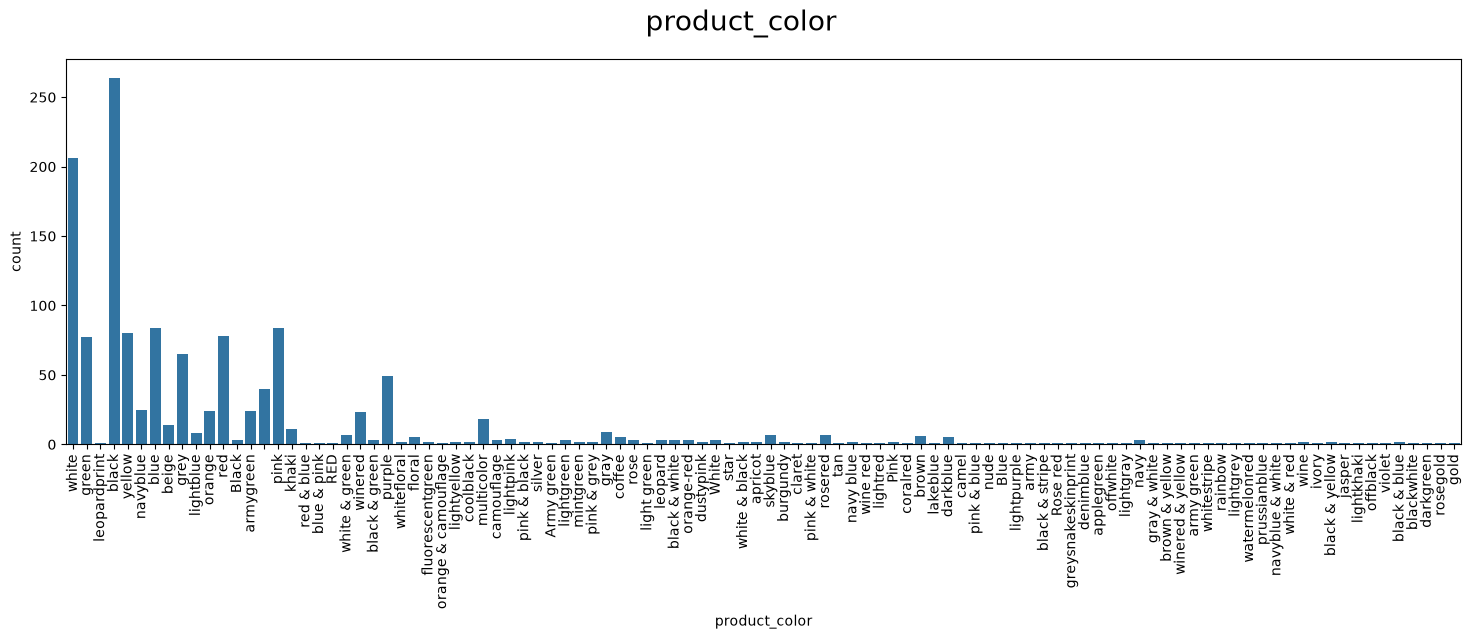

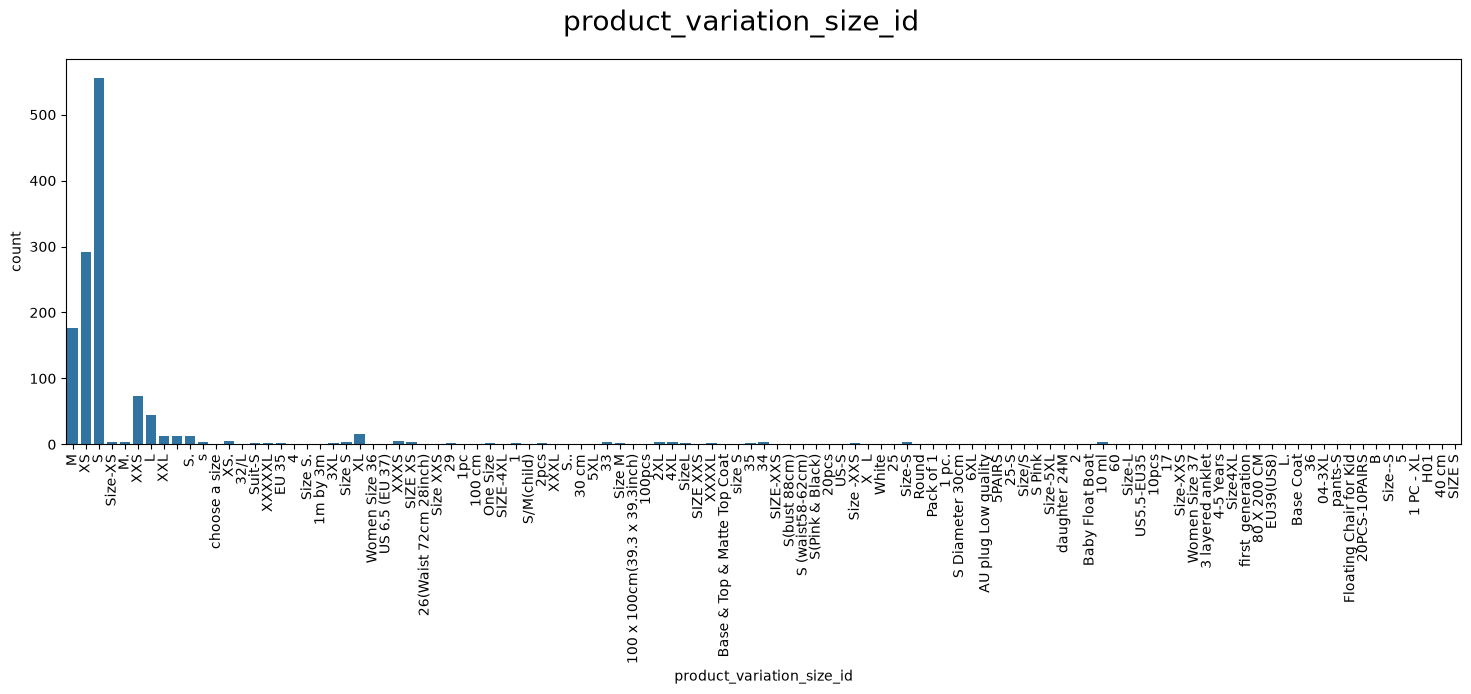

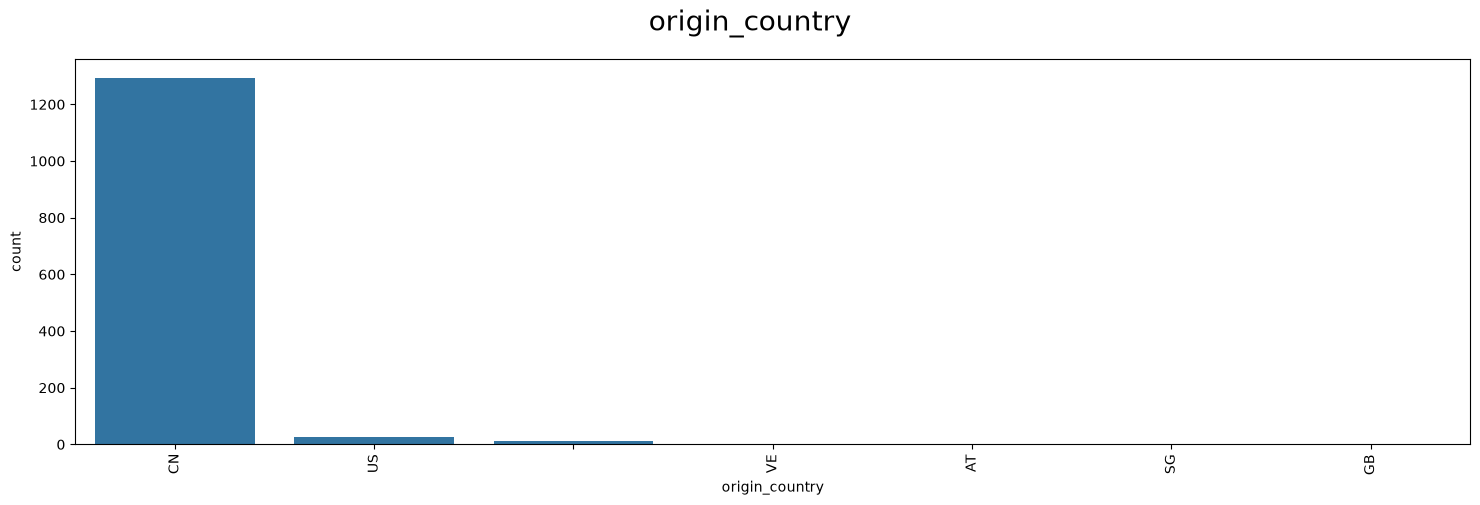

In [20]:
for col in categorical_cols:
    if col not in ["product_id", "title_orig", "tags"]:
        f, axes = plt.subplots(1,1,figsize=(18,5))
        sns.countplot(x=col, data = df_products)
        plt.xticks(rotation=90)
        plt.suptitle(col,fontsize=20)
        plt.show()

#### 2.1.2. Dados numéricos

In [21]:
numerical_cols

Index(['price', 'retail_price', 'units_sold', 'uses_ad_boosts', 'rating',
       'rating_count', 'badges_count', 'badge_local_product',
       'badge_product_quality', 'badge_fast_shipping',
       'product_variation_inventory', 'shipping_is_express',
       'countries_shipped_to', 'inventory_total', 'has_urgency_banner',
       'merchant_rating_count', 'merchant_rating'],
      dtype='str')

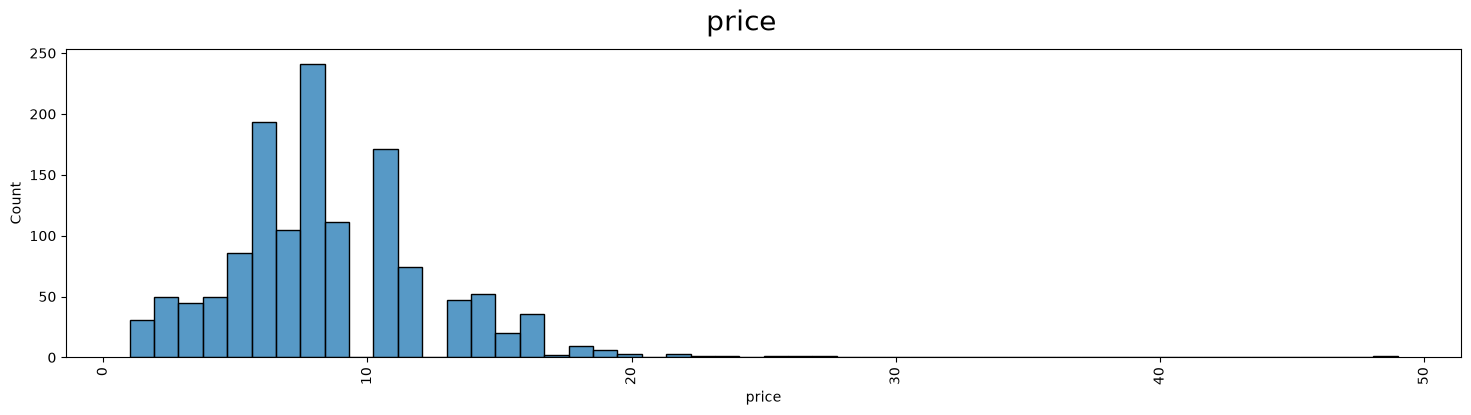

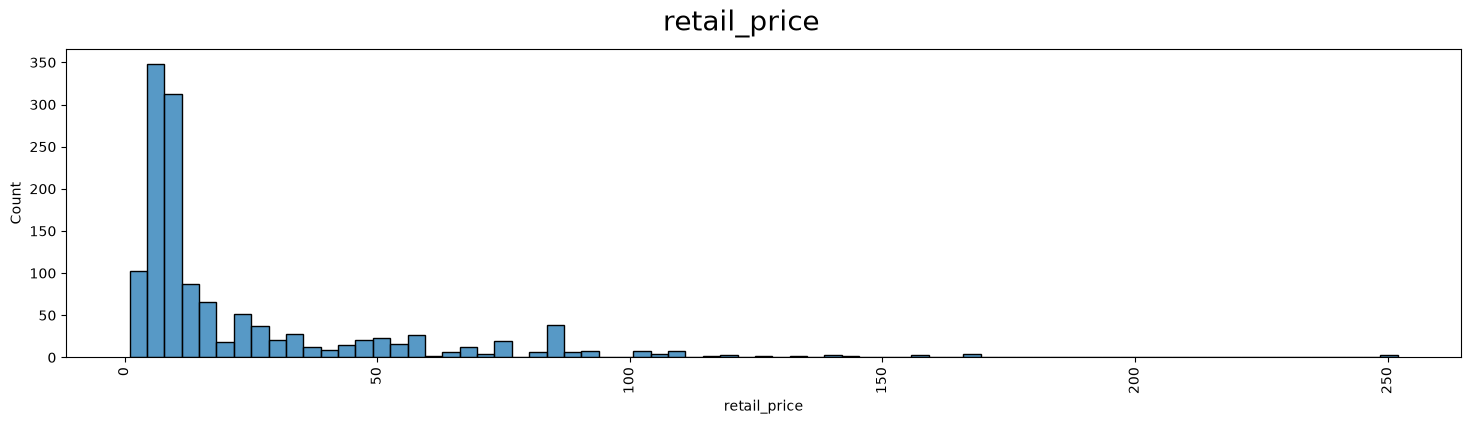

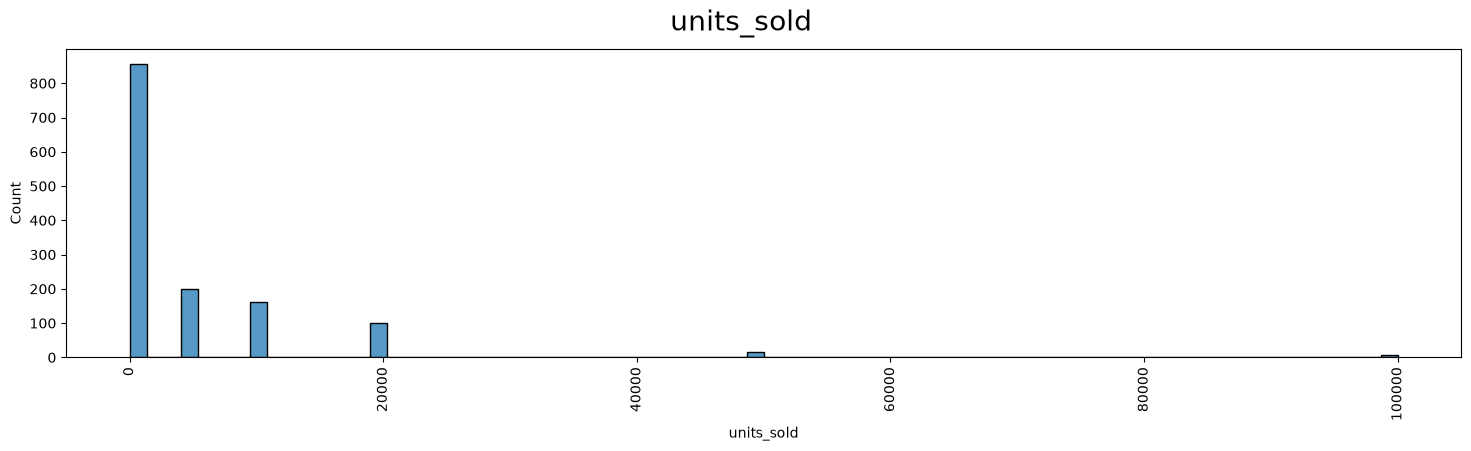

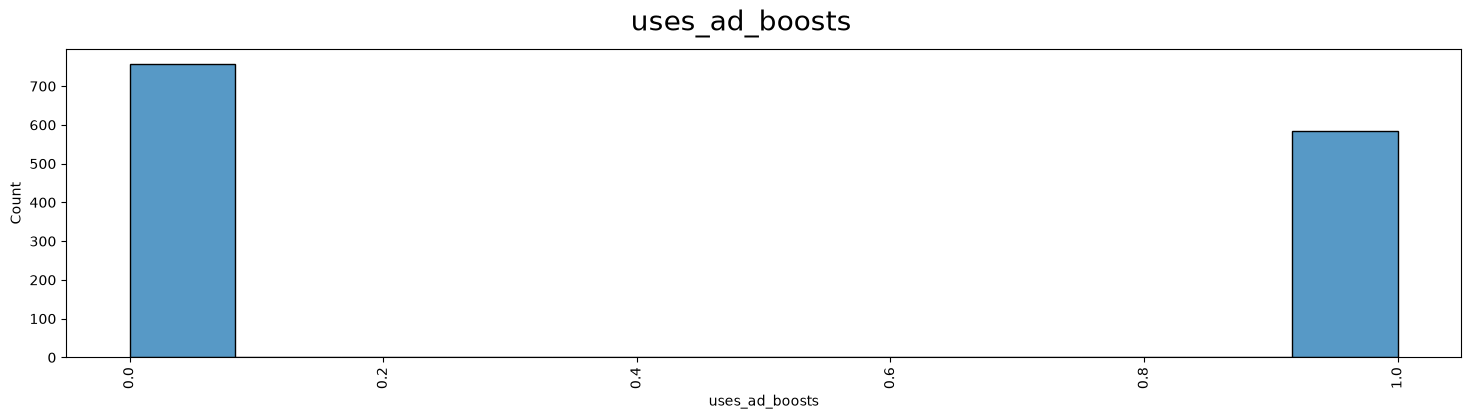

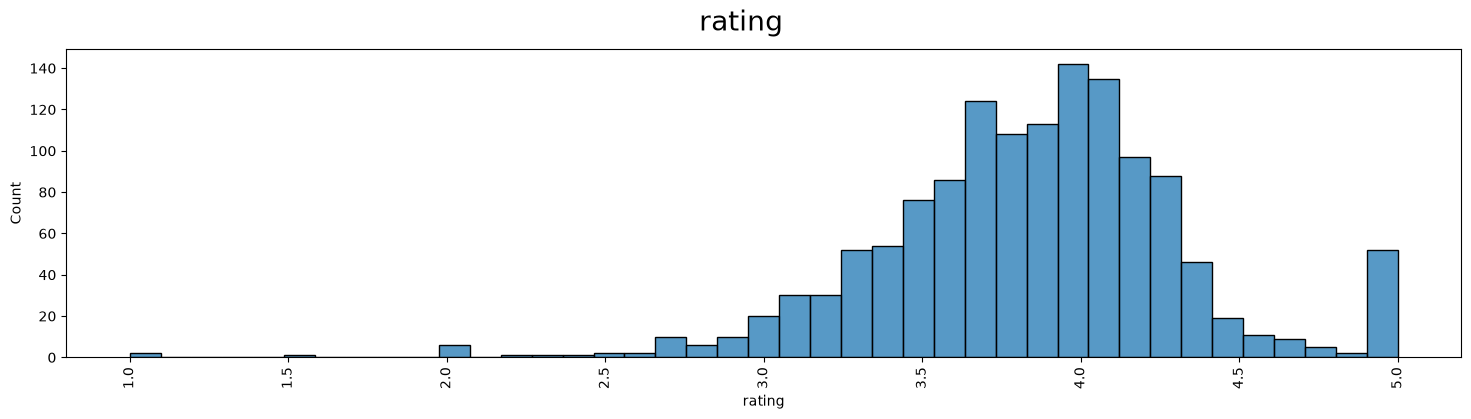

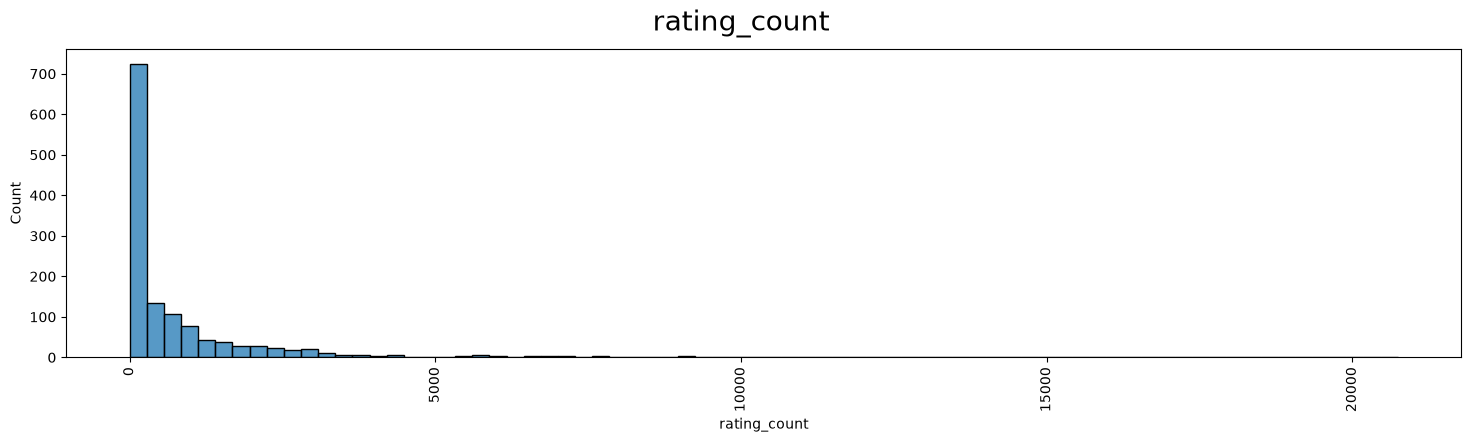

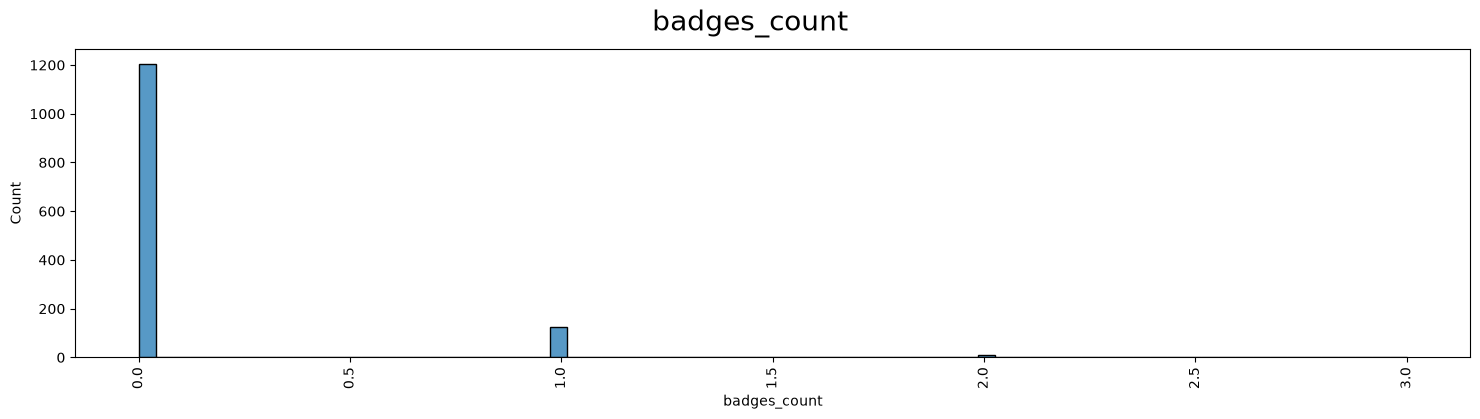

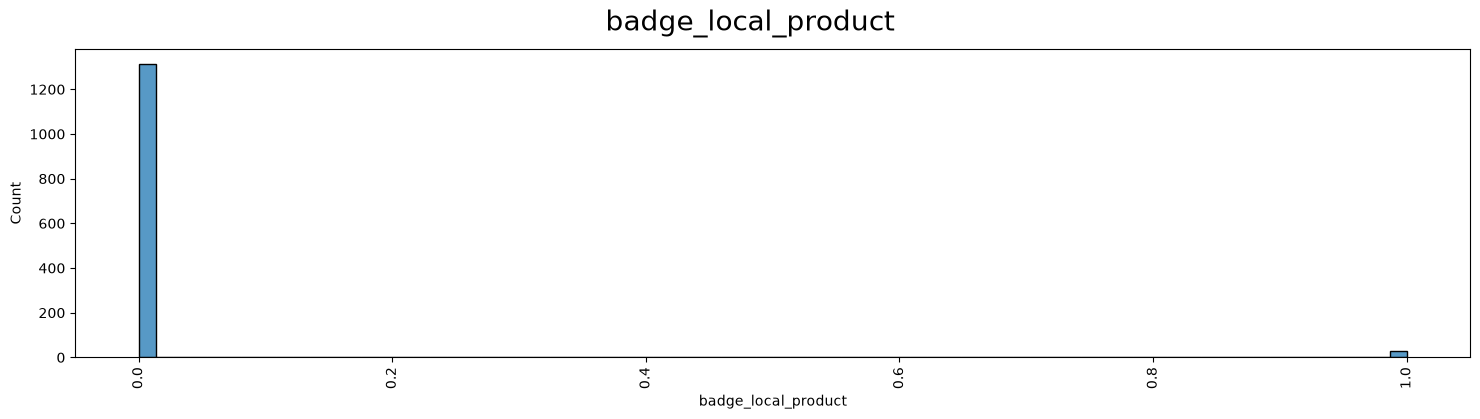

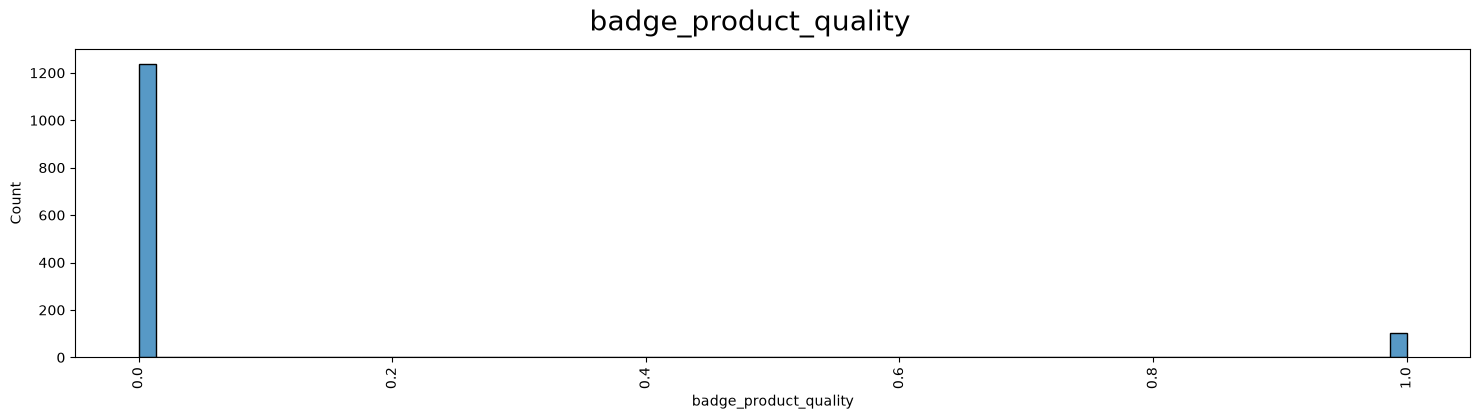

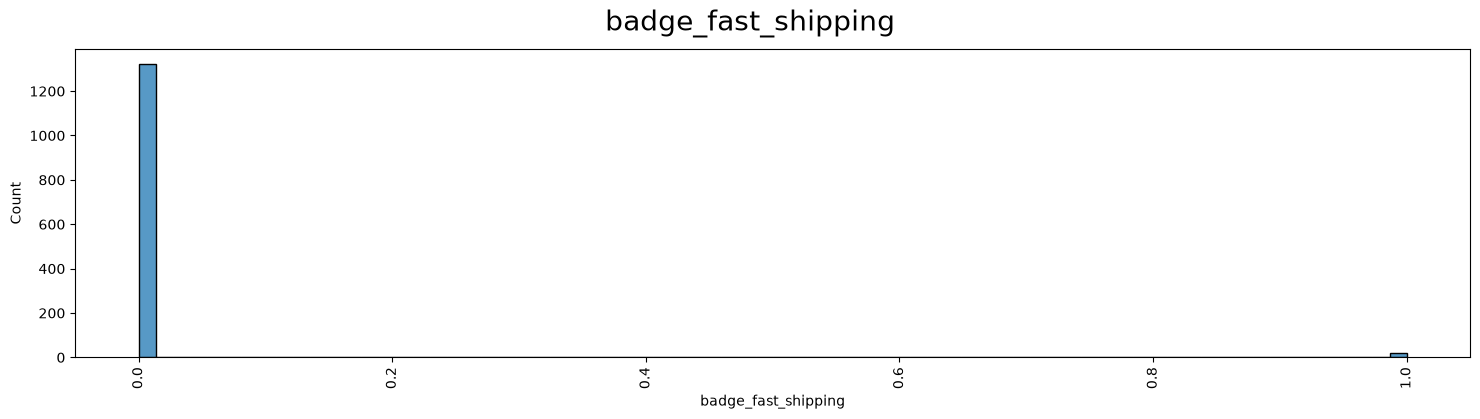

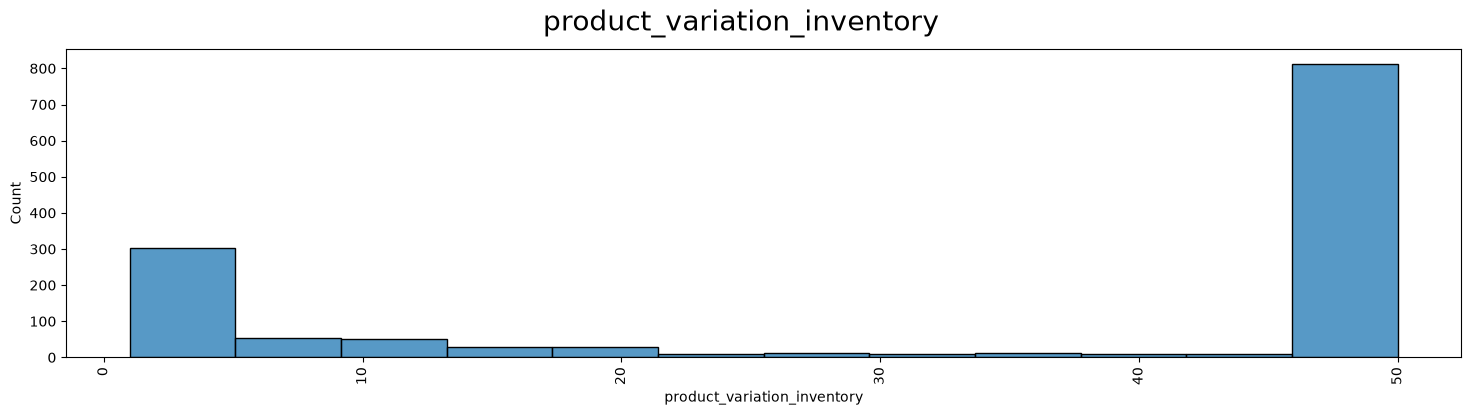

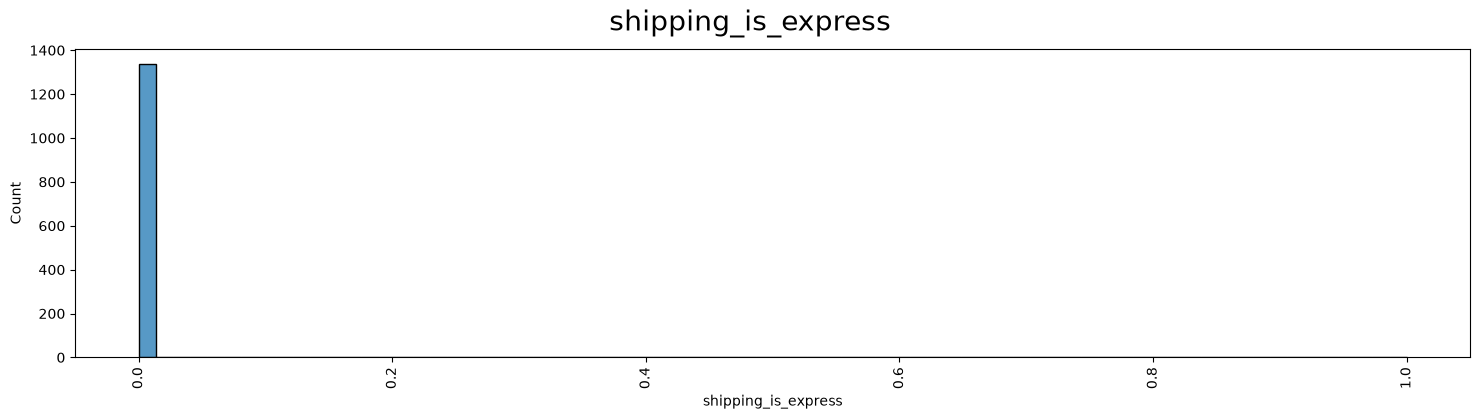

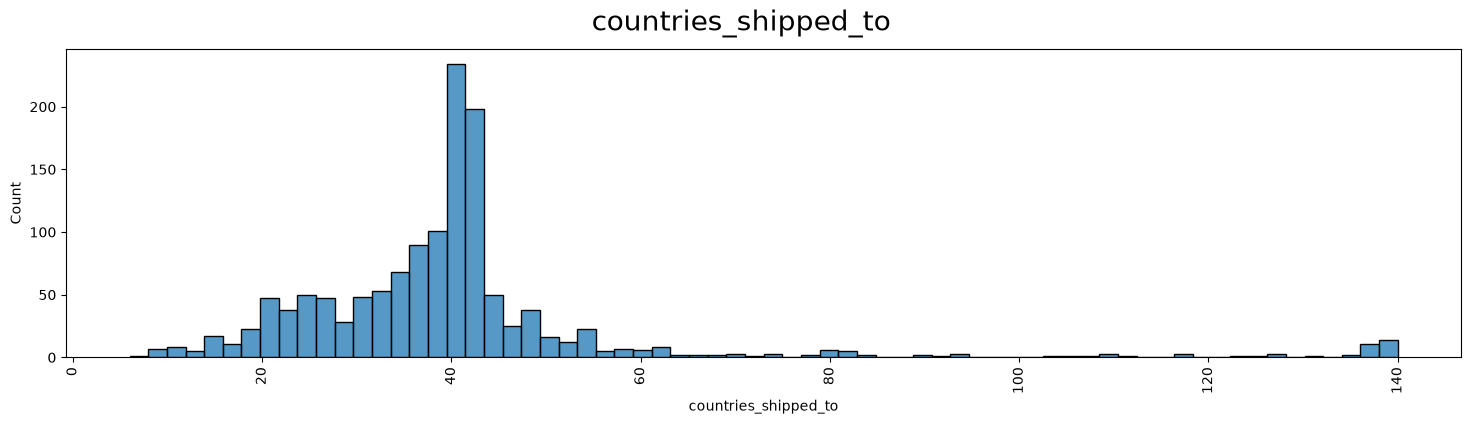

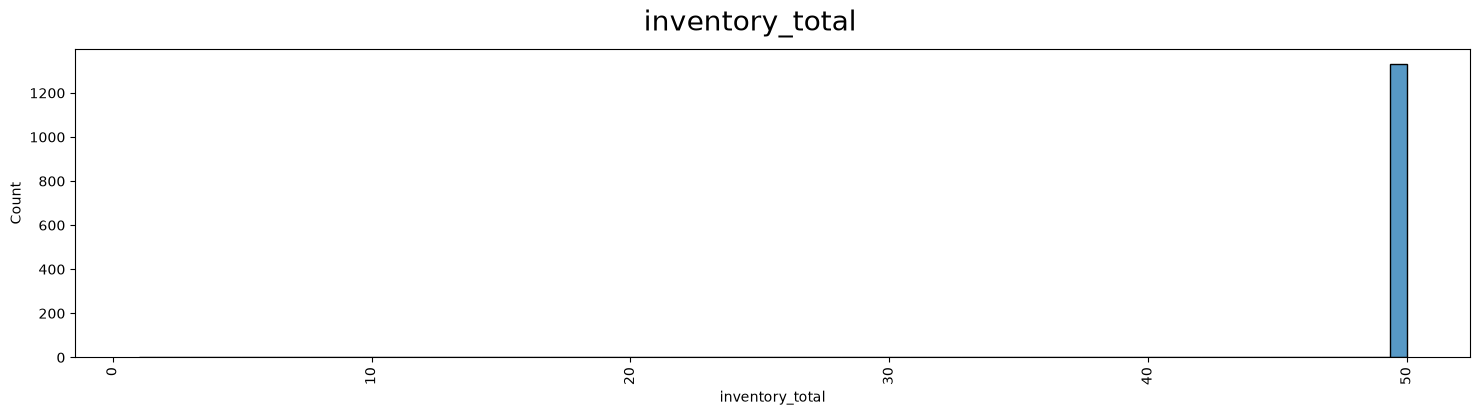

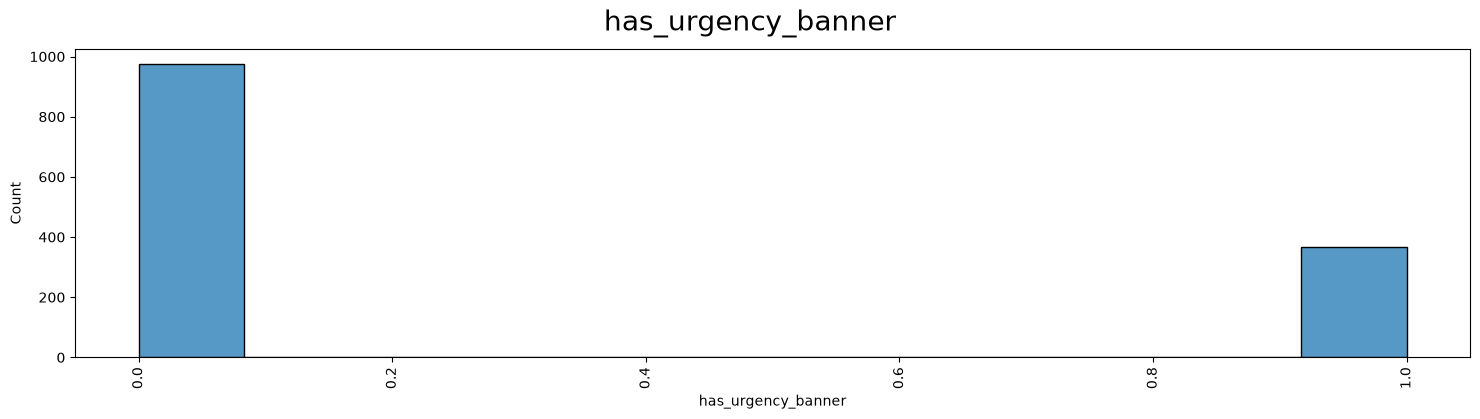

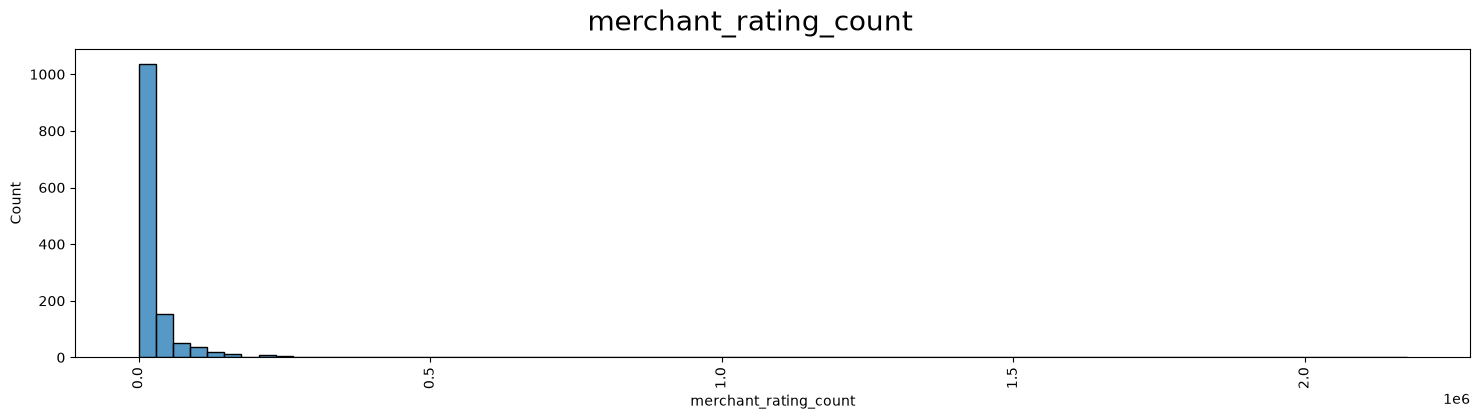

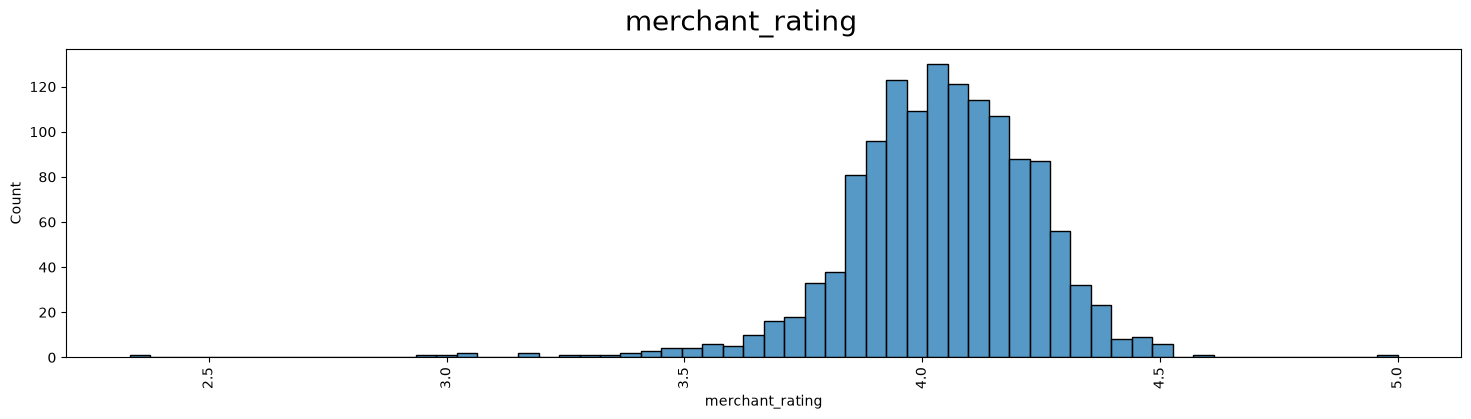

In [22]:
for col in numerical_cols:
    f, axes = plt.subplots(1,1,figsize=(18,4))
    sns.histplot(x=col, data=df_products)
    plt.xticks(rotation=90)
    plt.suptitle(col,fontsize=20)
    plt.show()

A coluna "units_sold" precisará de uma correção, pois não é contínua
Deveria entrar como variável CATEGÓRICA

#### 2.1.3. Ajuste fino das colunas "tag" e "units sold"

** units_sold**

In [23]:
df_products["units_sold"].value_counts()

units_sold
100       396
1000      362
5000      200
10000     163
20000      99
50         50
10         36
50000      17
100000      6
1           3
7           2
2           2
3           2
8           2
6           1
Name: count, dtype: int64

In [24]:
df_products["units_sold"].median()

np.float64(1000.0)

In [25]:
df_products["units_sold"].mean()

np.float64(4820.662938105891)

In [26]:
df_products.loc[df_products["units_sold"] < 10, "units_sold"] = 10
df_products["units_sold"].value_counts()

units_sold
100       396
1000      362
5000      200
10000     163
20000      99
50         50
10         48
50000      17
100000      6
Name: count, dtype: int64

Como a mediana das vendas é 1000, vamos tentar entender que produtos ficaram acima desse patamar e quais ficaram abaixo.

In [27]:
df_products["income"] = df_products["price"] * df_products["units_sold"]

<Axes: xlabel='income', ylabel='Count'>

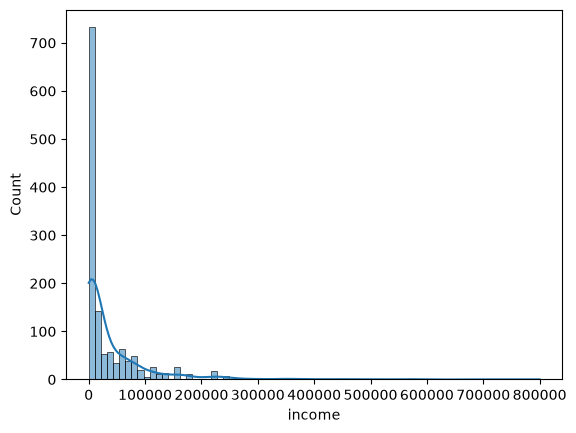

In [28]:
sns.histplot(df_products["income"], kde=True)

In [29]:
df_products["income"].median()

np.float64(8000.0)

In [30]:
df_products["income"].mean()

np.float64(39044.04071588367)

**Definição de sucesso:** vamos considerar sucesso o produto com **1.000 unidades vendidas ou mais** (a mediana).

Usar o faturamento (price * units_sold) colocaria o preço dentro da definição do sucesso. Aí o preço deixaria de ser algo que podemos analisar como fator e o modelo aprenderia parte da própria fórmula.

**Tag**

In [31]:
from wordcloud import WordCloud, STOPWORDS

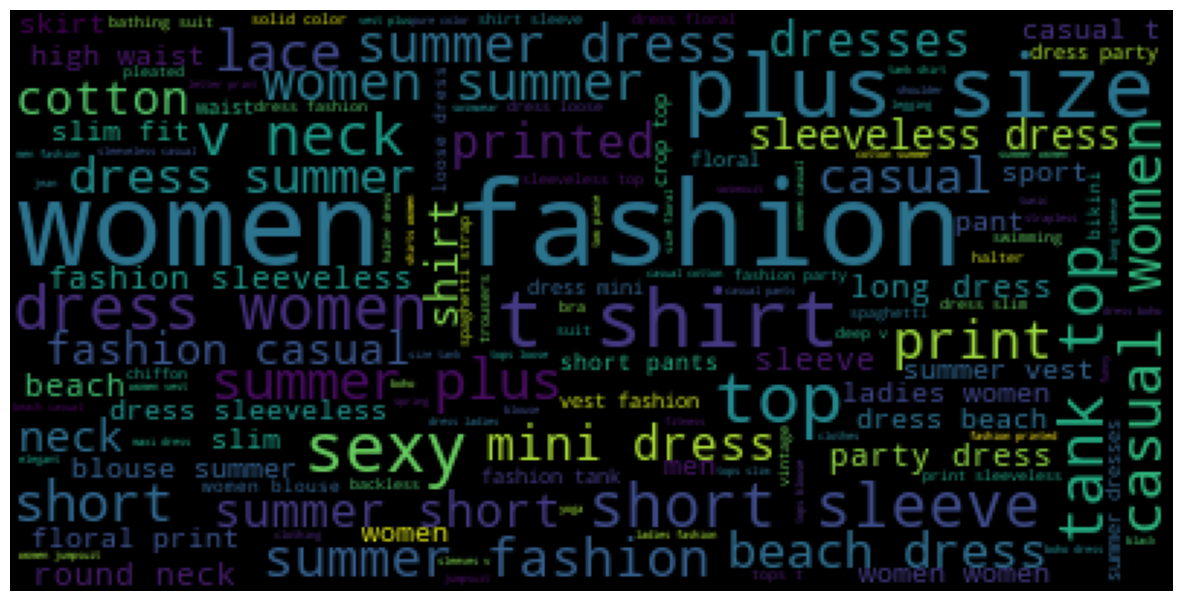

In [32]:
word_string=" ".join(df_products['tags'].str.lower())
wordcloud = WordCloud(stopwords=STOPWORDS).generate(word_string)

plt.subplots(figsize=(15,15))
plt.clf()
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

### 2.2. Análise de produtos "campeões"

In [33]:
df_products["success"] = 0
df_products.loc[df_products["units_sold"] >= 1000, "success"] = 1

df_products["success"].value_counts()

success
1    847
0    494
Name: count, dtype: int64

#### Produtos com maior diferença entre "retail_price" e "price" vendem mais?**

In [34]:
df_products.columns

Index(['product_id', 'title_orig', 'price', 'retail_price', 'units_sold',
       'uses_ad_boosts', 'rating', 'rating_count', 'badges_count',
       'badge_local_product', 'badge_product_quality', 'badge_fast_shipping',
       'tags', 'product_color', 'product_variation_size_id',
       'product_variation_inventory', 'shipping_is_express',
       'countries_shipped_to', 'inventory_total', 'has_urgency_banner',
       'origin_country', 'merchant_rating_count', 'merchant_rating', 'income',
       'success'],
      dtype='str')

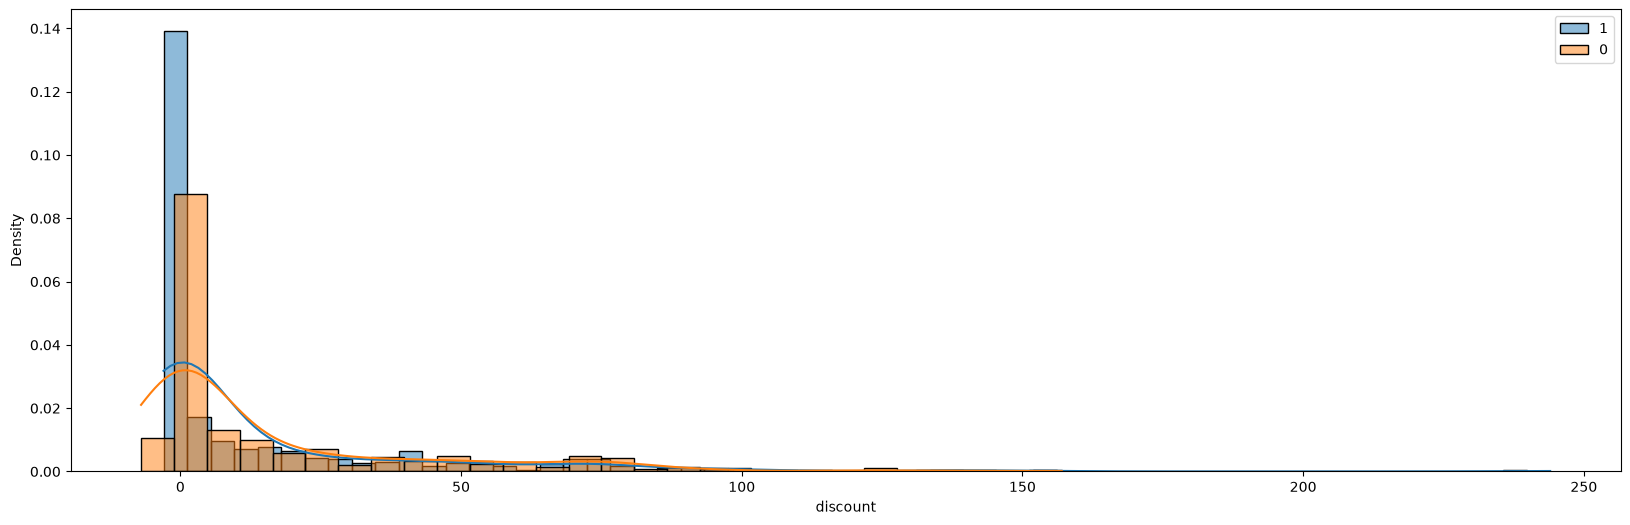

In [35]:
df_products["discount"] = df_products["retail_price"] - df_products["price"]

fig, ax = plt.subplots(figsize=(20, 6))
sns.histplot(df_products.loc[df_products["success"] == 1, "discount"], label="1", kde=True, stat="density")
sns.histplot(df_products.loc[df_products["success"] == 0, "discount"], label="0", kde=True, stat="density")
plt.legend()

In [36]:
discount_sucesso = df_products.loc[df_products["success"] == 1, "discount"].dropna()
discount_demais = df_products.loc[df_products["success"] == 0, "discount"].dropna()

print("Desconto - mediana sucesso:", discount_sucesso.median(), "| mediana demais:", discount_demais.median())
print("p-valor (Mann-Whitney):", mannwhitneyu(discount_sucesso, discount_demais).pvalue)

Desconto - mediana sucesso: 0.0 | mediana demais: 1.645
p-valor (Mann-Whitney): 0.011009887161714096


**Conclusão:** os produtos de sucesso têm desconto *menor* (mediana de 0 € contra 1,65 € nos demais, p = 0,01). A diferença entre o preço de retail e o preço praticado não ajuda a vender. Se tiver algum efeito, é na direção contrária.

#### Ad boost aumentam as vendas?

In [37]:
df_products.head(1)

,product_id,title_orig,price,retail_price,units_sold,uses_ad_boosts,rating,rating_count,badges_count,badge_local_product,...,shipping_is_express,countries_shipped_to,inventory_total,has_urgency_banner,origin_country,merchant_rating_count,merchant_rating,income,success,discount
0,5e9ae51d43d6a96e303acdb0,2020 Summer Vintage Flamingo Print Pajamas Se...,16.0,14,100,0,3.76,54,0,0,...,0,34,50,1.0,CN,568,4.128521,1600.0,0,-2.0


In [38]:
df_products.loc[df_products["success"] == 0, "uses_ad_boosts"].value_counts()

uses_ad_boosts
0    276
1    218
Name: count, dtype: int64

In [39]:
df_products.loc[df_products["success"] == 1, "uses_ad_boosts"].value_counts()

uses_ad_boosts
0    481
1    366
Name: count, dtype: int64

In [40]:
print(df_products.groupby("uses_ad_boosts")["success"].agg(["mean", "count"]))
tabela = pd.crosstab(df_products["uses_ad_boosts"], df_products["success"])
print("p-valor (qui-quadrado):", chi2_contingency(tabela).pvalue)

                    mean  count
uses_ad_boosts                 
0               0.635403    757
1               0.626712    584
p-valor (qui-quadrado): 0.7871335647080674


**Conclusão:** não há diferença. A taxa de sucesso é de 62,7% com ad boost e 63,5% sem (p = 0,79). O ad boost, sozinho, não está ligado a mais vendas.

#### Avaliações melhores aumentam vendas?


In [41]:
# Produtos sem nenhuma avaliação aparecem com nota 5.0, que não é uma nota real
print("Produtos sem avaliação:", (df_products["rating_count"] == 0).sum())
df_products.loc[df_products["rating_count"] == 0, "rating"] = np.nan

Produtos sem avaliação: 35


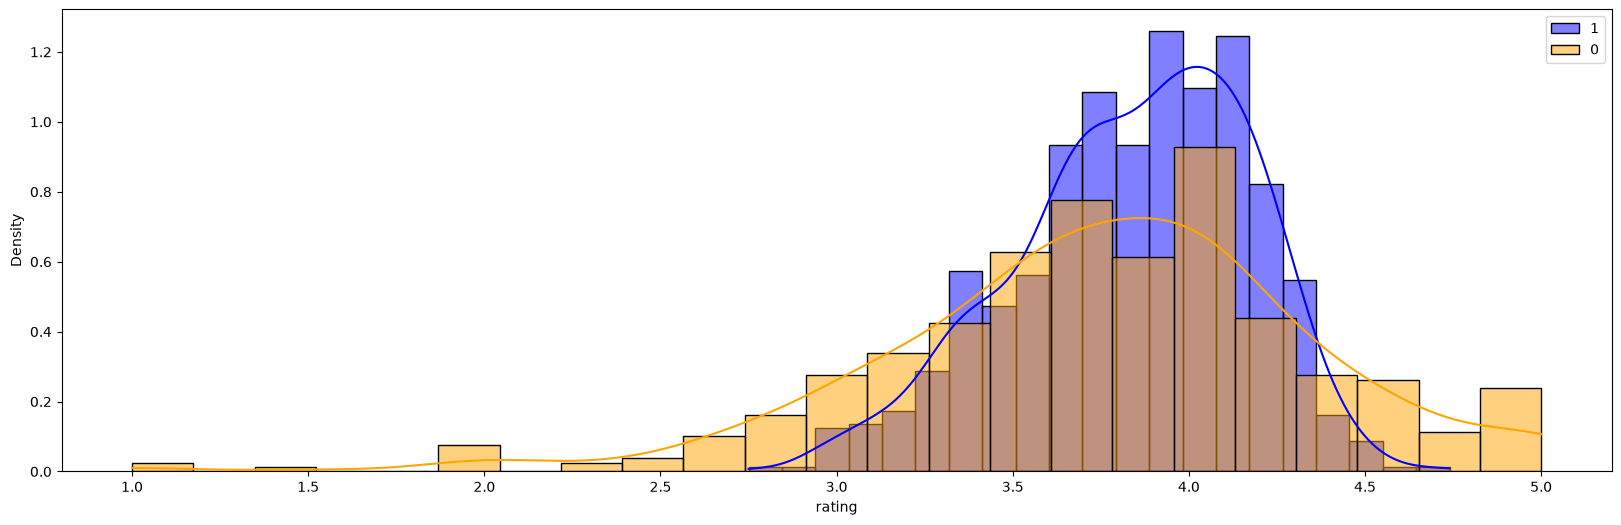

In [42]:
fig, ax = plt.subplots(figsize=(20, 6))
sns.histplot(df_products.loc[df_products["success"] == 1, "rating"], label="1", color="blue", kde=True, stat="density")
sns.histplot(df_products.loc[df_products["success"] == 0, "rating"], label="0", color="orange", kde=True, stat="density")
plt.legend()

In [43]:
rating_sucesso = df_products.loc[df_products["success"] == 1, "rating"].dropna()
rating_demais = df_products.loc[df_products["success"] == 0, "rating"].dropna()

print("Rating - mediana sucesso:", rating_sucesso.median(), "| mediana demais:", rating_demais.median())
print("p-valor (Mann-Whitney):", mannwhitneyu(rating_sucesso, rating_demais).pvalue)

Rating - mediana sucesso: 3.88 | mediana demais: 3.78
p-valor (Mann-Whitney): 0.004379705713847987


**Conclusão:** produtos de sucesso têm nota um pouco maior (mediana de 3,88 vs. 3,78, p = 0,004). A diferença é pequena e precisa de cuidado na leitura: a nota só existe depois que o produto vende e é avaliado, então ela é tanto consequência quanto causa das vendas.

#### Badges importam?

In [44]:
df_products.groupby(["success", "badges_count"]).count()[["title_orig"]].pivot_table(index="success", columns="badges_count").fillna(0)

title_orig                 
badges_count          0      1    2    3
success                                 
0                 462.0   25.0  7.0  0.0
1                 742.0  100.0  3.0  2.0

In [45]:
df_products.groupby(["success", "badge_product_quality"]).count()[["title_orig"]].pivot_table(index="success", columns="badge_product_quality").fillna(0)

title_orig      
badge_product_quality          0     1
success                               
0                          475.0  19.0
1                          762.0  85.0

In [46]:
df_products.groupby(["success", "badge_fast_shipping"]).count()[["title_orig"]].pivot_table(index="success", columns="badge_fast_shipping").fillna(0)

title_orig      
badge_fast_shipping          0     1
success                             
0                        482.0  12.0
1                        840.0   7.0

In [47]:
print(df_products.groupby("badge_product_quality")["success"].agg(["mean", "count"]))
tabela = pd.crosstab(df_products["badge_product_quality"], df_products["success"])
print("p-valor (qui-quadrado):", chi2_contingency(tabela).pvalue)

                           mean  count
badge_product_quality                 
0                      0.616006   1237
1                      0.817308    104
p-valor (qui-quadrado): 6.843426369707157e-05


In [48]:
print(df_products.groupby("badge_fast_shipping")["success"].agg(["mean", "count"]))
tabela = pd.crosstab(df_products["badge_fast_shipping"], df_products["success"])
print("p-valor (qui-quadrado):", chi2_contingency(tabela).pvalue)

                         mean  count
badge_fast_shipping                 
0                    0.635401   1322
1                    0.368421     19
p-valor (qui-quadrado): 0.0310909615517507


**Conclusão:**
- **Badge de qualidade:** 81,7% dos produtos com o badge são sucesso, contra 61,6% sem (p < 0,001). Mas o badge é dado com base nas avaliações, então também é consequência das vendas.
- **Badge de envio rápido:** a taxa de sucesso é menor (36,8% vs. 63,5%, p = 0,03), mas só 19 produtos têm esse badge. É pouco para tirar conclusão.

#### Quantidade de tags auxiliam vendas?

In [49]:
df_products["tags"]

0       Summer,Fashion,womenunderwearsuit,printedpajam...
1       Mini,womens dresses,Summer,Patchwork,fashion d...
2       Summer,cardigan,women beachwear,chiffon,Sexy w...
3       Summer,Shorts,Cotton,Cotton T Shirt,Sleeve,pri...
4       Summer,Plus Size,Lace,Casual pants,Bottom,pant...
                              ...                        
1336    Summer,Leggings,Fashion,high waist,pants,slim,...
1337    bodycon jumpsuits,nightwear,Shorts,slim,Body S...
1338    bohemia,Plus Size,dandelionfloralprinted,short...
1339    runningshort,Beach Shorts,beachpant,menbeachsh...
1340    Summer,Leggings,slim,Yoga,pants,Slim Fit,Women...
Name: tags, Length: 1341, dtype: str

In [50]:
df_products["tags_count"] = df_products["tags"].apply(lambda x: len(x.split(",")))

In [51]:
df_products["tags_count"]

0       24
1       15
2       19
3       18
4       13
        ..
1336    11
1337    14
1338    24
1339    12
1340    12
Name: tags_count, Length: 1341, dtype: int64

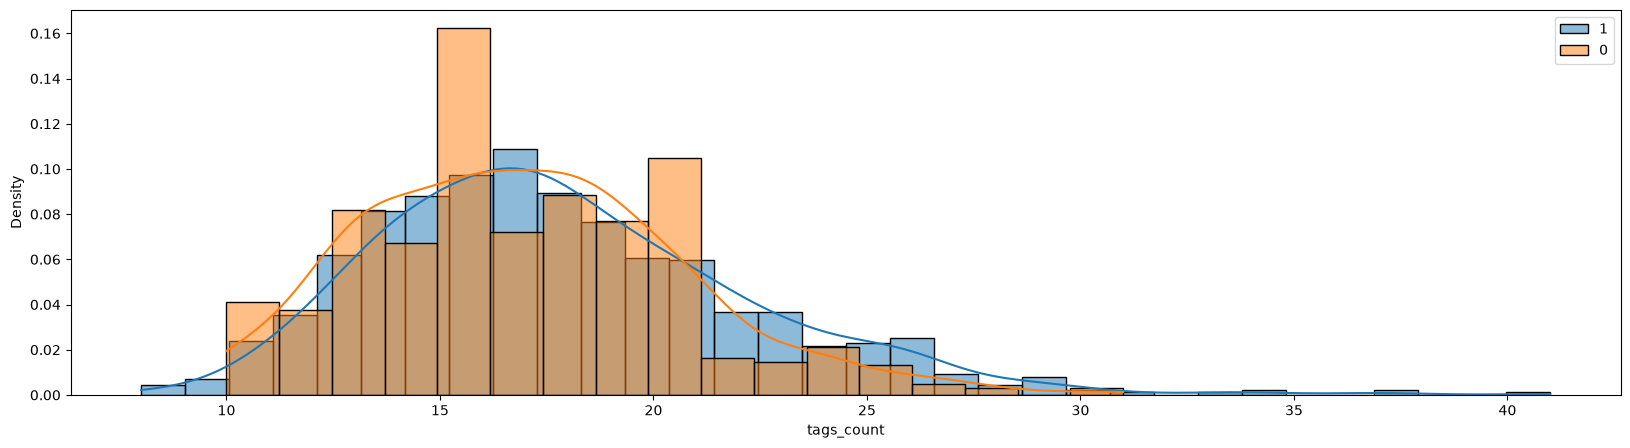

In [52]:
df_products["discount"] = df_products["retail_price"] - df_products["price"]

fig, ax = plt.subplots(figsize=(20, 5))
sns.histplot(df_products.loc[df_products["success"] == 1, "tags_count"], label="1", kde=True, stat="density")
sns.histplot(df_products.loc[df_products["success"] == 0, "tags_count"], label="0", kde=True, stat="density")
plt.legend()

In [53]:
tags_count_sucesso = df_products.loc[df_products["success"] == 1, "tags_count"].dropna()
tags_count_demais = df_products.loc[df_products["success"] == 0, "tags_count"].dropna()

print("Quantidade de tags - mediana sucesso:", tags_count_sucesso.median(), "| mediana demais:", tags_count_demais.median())
print("p-valor (Mann-Whitney):", mannwhitneyu(tags_count_sucesso, tags_count_demais).pvalue)

Quantidade de tags - mediana sucesso: 17.0 | mediana demais: 17.0
p-valor (Mann-Whitney): 0.0005337199187631688


**Conclusão:** a mediana é igual nos dois grupos (17 tags). O teste aponta diferença porque os produtos de sucesso usam um pouco mais de tags, mas o efeito na prática é pequeno.

#### Tags com maiores vendas?

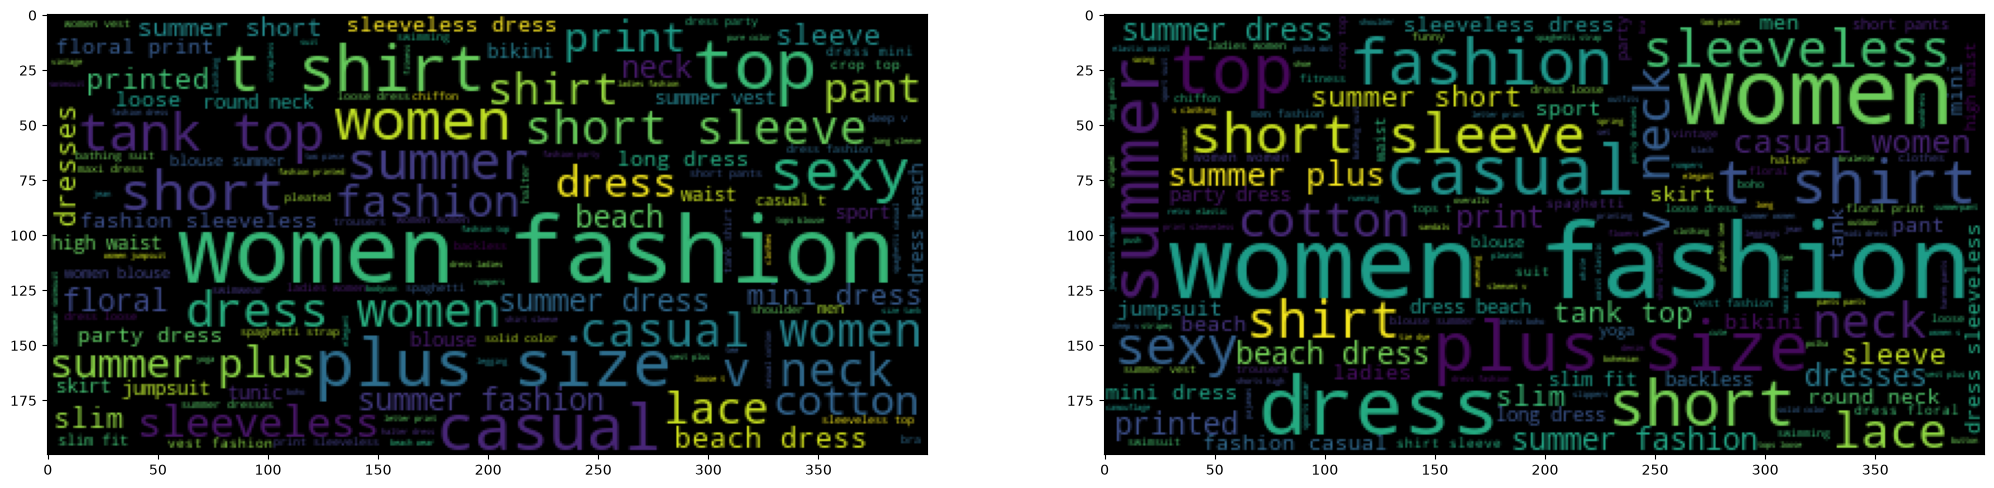

In [54]:
df_success_tags = df_products.loc[df_products["success"] == 1]
word_string=" ".join(df_success_tags['tags'].str.lower())
wordcloud_success = WordCloud(stopwords=STOPWORDS).generate(word_string)

df_fail_tags = df_products.loc[df_products["success"] == 0]
word_string=" ".join(df_fail_tags['tags'].str.lower())
wordcloud_fail = WordCloud(stopwords=STOPWORDS).generate(word_string)

fig, ax = plt.subplots(1, 2, figsize=(25,20))
ax[0].imshow(wordcloud_success)
ax[1].imshow(wordcloud_fail)

plt.show()

**Que palavras aparecem mais nos produtos que vendem mais e menos?**

In [55]:
tags = []
for list_tags in df_success_tags["tags"].values:
    tags += list_tags.split(",")
pd.Series(tags).value_counts().head(5)

Women's Fashion    735
Summer             656
Fashion            595
Women              547
Casual             487
Name: count, dtype: int64

In [56]:
tags = []
for list_tags in df_fail_tags["tags"].values:
    tags += list_tags.split(",")
pd.Series(tags).value_counts().head(5)

Summer             450
Women's Fashion    385
Fashion            336
Women              279
Casual             266
Name: count, dtype: int64

**Conclusão:** as tags mais usadas são praticamente as mesmas nos dois grupos (Women's Fashion, Summer, Fashion, Women, Casual). Não aparece um nicho de tags claramente ligado ao sucesso: a categoria (moda feminina de verão) domina a base inteira.

#### O frete influencia as vendas?

In [57]:
print(df_products.groupby("shipping_is_express")["success"].agg(["mean", "count"]))
tabela = pd.crosstab(df_products["shipping_is_express"], df_products["success"])
print("p-valor (qui-quadrado):", chi2_contingency(tabela).pvalue)

                         mean  count
shipping_is_express                 
0                    0.632012   1337
1                    0.500000      4
p-valor (qui-quadrado): 0.9780756230001303


In [58]:
countries_shipped_to_sucesso = df_products.loc[df_products["success"] == 1, "countries_shipped_to"].dropna()
countries_shipped_to_demais = df_products.loc[df_products["success"] == 0, "countries_shipped_to"].dropna()

print("Países atendidos - mediana sucesso:", countries_shipped_to_sucesso.median(), "| mediana demais:", countries_shipped_to_demais.median())
print("p-valor (Mann-Whitney):", mannwhitneyu(countries_shipped_to_sucesso, countries_shipped_to_demais).pvalue)

Países atendidos - mediana sucesso: 40.0 | mediana demais: 40.0
p-valor (Mann-Whitney): 0.1718130882360137


**Conclusão:** o frete não faz diferença. Só 4 produtos usam frete expresso, o que não permite conclusão, e o número de países atendidos tem a mesma mediana (40) nos dois grupos (p = 0,17).

#### A reputação do vendedor importa?

In [59]:
merchant_rating_sucesso = df_products.loc[df_products["success"] == 1, "merchant_rating"].dropna()
merchant_rating_demais = df_products.loc[df_products["success"] == 0, "merchant_rating"].dropna()

print("Nota do vendedor - mediana sucesso:", merchant_rating_sucesso.median(), "| mediana demais:", merchant_rating_demais.median())
print("p-valor (Mann-Whitney):", mannwhitneyu(merchant_rating_sucesso, merchant_rating_demais).pvalue)

Nota do vendedor - mediana sucesso: 4.066326401056347 | mediana demais: 4.005969722659568
p-valor (Mann-Whitney): 1.4254149783017973e-07


**Conclusão:** os produtos de sucesso vêm de vendedores com nota um pouco maior (mediana de 4,07 vs. 4,01). A diferença é pequena, mas é a mais consistente da análise (p < 0,001).

## 3. Machine Learning

**Quais variáveis entram no modelo?** A ideia é prever o sucesso **antes** de colocar o produto à venda. Por isso ficam de fora as variáveis que só existem depois que o produto já vendeu:
- `rating`, `badge_product_quality` e `badges_count`: dependem das avaliações dos compradores;
- `inventory_total`, `product_variation_inventory` e `has_urgency_banner`: o estoque exibido (e o banner de "quantidade limitada") pode refletir o que já foi vendido.

In [60]:
from sklearn.model_selection import train_test_split

model_cols = ['price', 'retail_price',
       'uses_ad_boosts', 'badge_fast_shipping',
       'shipping_is_express', 'countries_shipped_to',
       'merchant_rating', 'discount', 'tags_count']

In [61]:
x = df_products[model_cols]
y = df_products["success"]

In [62]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42, stratify=y)

In [63]:
x_train

,price,retail_price,uses_ad_boosts,badge_fast_shipping,shipping_is_express,countries_shipped_to,merchant_rating,discount,tags_count
276,11.0,10,0,0,0,68,4.024055,-1.0,18
1124,9.0,31,1,0,0,34,4.165983,22.0,15
1328,8.0,7,0,0,0,36,4.127902,-1.0,18
700,5.0,5,1,0,0,40,3.038961,0.0,17
900,15.0,13,0,0,0,42,4.471018,-2.0,21
...,...,...,...,...,...,...,...,...,...
1081,13.0,252,0,0,0,35,4.097119,239.0,15
863,9.0,8,0,0,0,53,4.302082,-1.0,16
1034,6.0,7,0,0,0,40,3.950093,1.0,21
575,8.0,7,0,0,0,30,3.982400,-1.0,26


In [64]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_distributions = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [4, 6, 8, 10, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": ["sqrt", "log2", None],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=1),
    param_distributions=param_distributions,
    n_iter=20,
    scoring="roc_auc",
    cv=cv,
    random_state=42,
    n_jobs=-1,
)
random_search.fit(x_train, y_train)

print("Melhor ROC AUC (média da cross-validation):", random_search.best_score_)

Melhor ROC AUC (média da cross-validation): 0.6392503648474865


In [65]:
random_search.best_params_

{'n_estimators': 100,
 'min_samples_leaf': 5,
 'max_features': 'log2',
 'max_depth': 10}

In [66]:
rf_model = random_search.best_estimator_

In [67]:
rf_model

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'log2'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total nu

In [68]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = rf_model.predict(x_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print("ROC AUC (teste):", roc_auc_score(y_test, rf_model.predict_proba(x_test)[:, 1]))

              precision    recall  f1-score   support

           0       0.61      0.32      0.42       148
           1       0.69      0.88      0.77       255

    accuracy                           0.67       403
   macro avg       0.65      0.60      0.60       403
weighted avg       0.66      0.67      0.64       403

[[ 47 101]
 [ 30 225]]
ROC AUC (teste): 0.6646793852676206


**Conclusão:** com apenas as variáveis disponíveis antes da venda, o modelo prevê pouco. O ROC AUC é de 0,64 na cross-validation e 0,66 no teste. A acurácia de 67% fica pouco acima dos 63% que se teria chutando sempre "sucesso", e o modelo identifica só 32% dos produtos que não vendem bem. Isso mostra que as variáveis do anúncio (preço, desconto, ad boost, tags, frete) explicam pouco do sucesso de um produto.

**Feature importance**

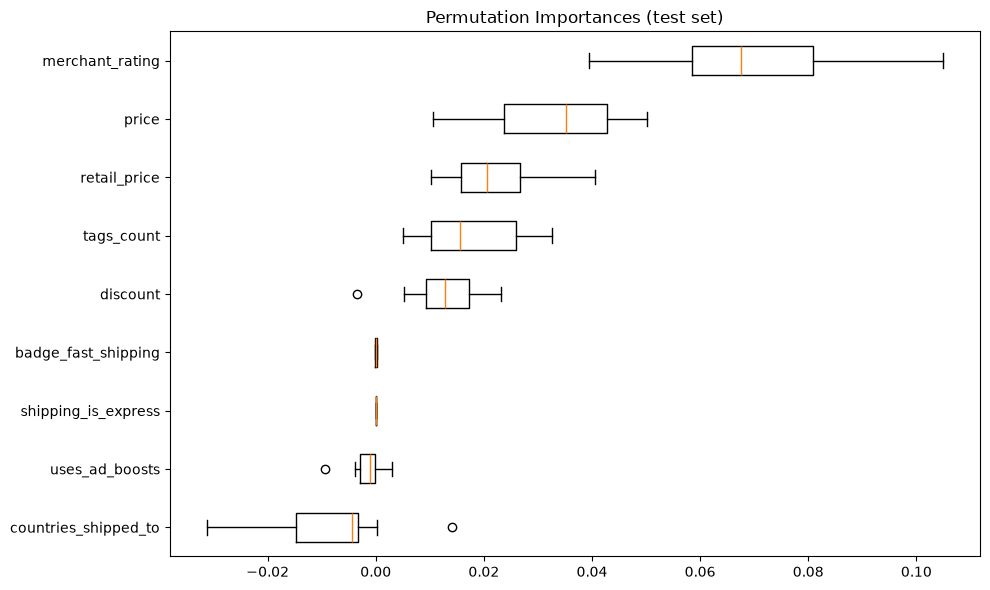

In [69]:
from sklearn.inspection import permutation_importance

result = permutation_importance(rf_model, x_test, y_test, n_repeats=10, random_state=42, scoring="roc_auc")
sorted_idx = result.importances_mean.argsort()

fig, ax = plt.subplots(figsize=(10, 6))
ax.boxplot(result.importances[sorted_idx].T, orientation="horizontal", tick_labels=x_test.columns[sorted_idx])
ax.set_title("Permutation Importances (test set)")
fig.tight_layout()
fig.savefig("../reports/figures/permutation_importance.png", bbox_inches="tight")
plt.show()

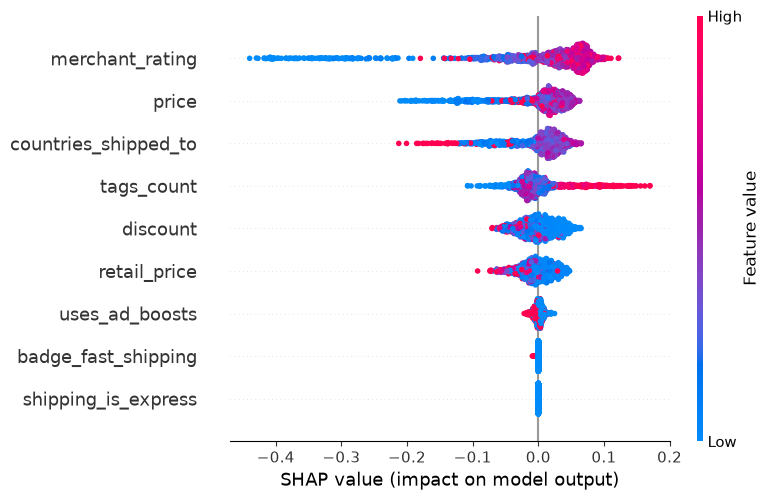

In [70]:
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(x)
shap.summary_plot(shap_values[:, :, 1], x)

**Conclusão:** a nota do vendedor (`merchant_rating`) é a variável mais importante, seguida de preço, preço de retail, quantidade de tags e desconto. Ad boost, frete expresso, badge de envio rápido e países atendidos praticamente não contribuem.

## 4. Conclusões

### Respostas às perguntas

| Pergunta | Resposta |
|---|---|
| Desconto (retail vs. price) aumenta vendas? | Não. Produtos de sucesso têm desconto menor |
| Ad boost aumenta vendas? | Não há diferença |
| Avaliações melhores aumentam vendas? | Diferença pequena, e a nota também é consequência das vendas |
| Badges importam? | O de qualidade acompanha o sucesso, mas depende das avaliações. Os outros têm poucos produtos |
| Quantidade de tags ajuda? | Efeito pequeno |
| Tags com maiores vendas? | Não há um nicho distinto: a mesma categoria domina os dois grupos |
| Frete importa? | Não |
| Reputação do vendedor importa? | Sim. É o fator mais consistente, na análise e no modelo |

### Recomendações para a empresa

1. **Cuidar da reputação desde o início.** A nota do vendedor é o fator mais ligado ao sucesso. Para uma conta nova, isso significa escolher bem os fornecedores e caprichar nos primeiros pedidos para acumular boas avaliações.
2. **Não contar com ad boost, desconto ou frete como alavancas principais.** Nenhum deles aparece ligado a mais vendas nesta base. Se forem usados, o ideal é testar (A/B) antes de investir mais.
3. **Não esperar que preço e configuração do anúncio garantam sucesso.** O modelo mostra que essas variáveis explicam pouco do resultado.

### Limitações

- **Sucesso definido por um corte:** 1.000 unidades, a mediana. Outros cortes poderiam mudar algumas conclusões.
- **Um único recorte:** produtos da busca "summer" em agosto de 2020. Os resultados podem não valer para outras épocas ou categorias.
- **Vendas acumuladas, sem data de lançamento:** produtos mais antigos tiveram mais tempo para vender.
- **Nota do vendedor medida depois das vendas:** ela também inclui as avaliações do próprio produto.
- **Associação não é causa:** as recomendações são hipóteses a validar com testes.